## **Preprocessing the Dataset**

1. Required Libraries To Import

In [31]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

2. loading Dataset

In [32]:
file_path = '/content/sample_data/Marketing_Analytics.xlsx'
df = pd.read_excel(file_path)
display(df.head())

,Campaign_ID,Campaign_Type,Region,Age_Group,Gender,Channel,Impressions,Month,Customer_Satisfaction,Bounce_Rate,Session_Duration,Device,Clicks,CTR,Leads,Conversions,Conversion_Rate,Ad_Spend,Revenue,ROI
0,CMP00001,PPC,South,18-25,Male,Google Ads,13434,Jul,1.7,68.29,2.17,Desktop,1148,8.55,61,14,22.95,3079.54,1348.15,-56.22
1,CMP00002,Influencer,South,36-45,Female,Facebook,63185,May,2.3,67.20,1.94,Tablet,7151,11.32,2196,321,14.62,2592.70,96647.90,3627.69
2,CMP00003,SEO,East,46-60,Male,Email,47096,Dec,2.5,31.97,10.78,Tablet,6269,13.31,991,326,32.90,4641.84,92599.81,1894.89
3,CMP00004,Influencer,West,18-25,Male,Google Ads,48471,Oct,3.0,47.23,5.05,Desktop,2000,4.13,402,141,35.07,5572.66,63656.12,1042.29
4,CMP00005,Influencer,North,46-60,Male,Instagram,57004,Mar,1.1,70.10,13.16,Mobile,2696,4.73,661,194,29.35,378.58,58755.38,15419.94


3. Dropping Campaign_Id column



In [33]:
if 'Campaign_ID' in df.columns:
  df = df.drop(columns = ['Campaign_ID'])

In [34]:
numerical_cols = df.select_dtypes(include = ['int64', 'float64']).columns

4. Applying Standard Scaling

In [35]:
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

5. Data Preprocessed

In [36]:
display(df.head())

,Campaign_Type,Region,Age_Group,Gender,Channel,Impressions,Month,Customer_Satisfaction,Bounce_Rate,Session_Duration,Device,Clicks,CTR,Leads,Conversions,Conversion_Rate,Ad_Spend,Revenue,ROI
0,PPC,South,18-25,Male,Google Ads,-1.287446,Jul,-1.122787,1.054646,-1.459393,Desktop,-0.879014,0.132291,-0.941583,-0.798139,-0.383636,-0.691763,-0.703911,-0.298171
1,Influencer,South,36-45,Female,Facebook,0.442467,May,-0.603311,0.991642,-1.516706,Tablet,0.947702,0.818858,1.410544,0.222993,-1.016610,-0.862462,0.274069,0.046934
2,SEO,East,46-60,Male,Email,-0.116970,Dec,-0.430152,-1.044723,0.686100,Tablet,0.679309,1.312096,0.082997,0.239624,0.372438,-0.143979,0.232527,-0.115393
3,Influencer,West,18-25,Male,Google Ads,-0.069159,Oct,0.002745,-0.162664,-0.741737,Desktop,-0.619750,-0.963242,-0.565904,-0.375716,0.537331,0.182391,-0.064497,-0.195263
4,Influencer,North,46-60,Male,Instagram,0.227545,Mar,-1.642264,1.159267,1.279164,Mobile,-0.407957,-0.814527,-0.280564,-0.199430,0.102683,-1.638791,-0.114790,1.151619


## **Key Performance Indicators**

Required Libraries

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

loading Dataset

In [38]:
## Loading the Dataset
file_path = '/content/sample_data/Marketing_Analytics.xlsx'
df = pd.read_excel(file_path)
df.head(5)

,Campaign_ID,Campaign_Type,Region,Age_Group,Gender,Channel,Impressions,Month,Customer_Satisfaction,Bounce_Rate,Session_Duration,Device,Clicks,CTR,Leads,Conversions,Conversion_Rate,Ad_Spend,Revenue,ROI
0,CMP00001,PPC,South,18-25,Male,Google Ads,13434,Jul,1.7,68.29,2.17,Desktop,1148,8.55,61,14,22.95,3079.54,1348.15,-56.22
1,CMP00002,Influencer,South,36-45,Female,Facebook,63185,May,2.3,67.20,1.94,Tablet,7151,11.32,2196,321,14.62,2592.70,96647.90,3627.69
2,CMP00003,SEO,East,46-60,Male,Email,47096,Dec,2.5,31.97,10.78,Tablet,6269,13.31,991,326,32.90,4641.84,92599.81,1894.89
3,CMP00004,Influencer,West,18-25,Male,Google Ads,48471,Oct,3.0,47.23,5.05,Desktop,2000,4.13,402,141,35.07,5572.66,63656.12,1042.29
4,CMP00005,Influencer,North,46-60,Male,Instagram,57004,Mar,1.1,70.10,13.16,Mobile,2696,4.73,661,194,29.35,378.58,58755.38,15419.94


Calculate global sums

In [39]:
total_spend = df['Ad_Spend'].sum()
total_clicks = df['Clicks'].sum()
total_leads = df['Leads'].sum()
total_conversions = df['Conversions'].sum()
total_revenue = df['Revenue'].sum()
total_impressions = df['Impressions'].sum()

Caluculate KPI's

In [40]:
cpc = total_spend / total_clicks if total_clicks else 0
cpl = total_spend / total_leads if total_leads else 0
cpa = total_spend / total_conversions if total_conversions else 0
rpc = total_revenue / total_clicks if total_clicks else 0
rpcon = total_revenue / total_conversions if total_conversions else 0
roas = total_revenue / total_spend if total_spend else 0
ctr = (total_clicks / total_impressions) * 100 if total_impressions else 0
conversion_rate = (total_conversions / total_clicks) * 100 if total_clicks else 0

In [41]:
kpis = {
    "CPC\n(Cost Per Click)": f"${cpc:.2f}",
    "CPL\n(Cost Per Lead)": f"${cpl:.2f}",
    "CPA\n(Cost Per Conversion)": f"${cpa:.2f}",
    "RPC\n(Revenue Per Click)": f"${rpc:.2f}",
    "RPCON\n(Revenue Per Conversion)": f"${rpcon:.2f}",
    "ROAS\n(Return On Ad Spend)": f"{roas:.2f}",
    "CTR\n(Click - Through Rate)": f"${ctr:.2f}",
    "Conv. Rate\n(Conversion Rate)": f"{conversion_rate:.2f}"
}

Visualization Setup

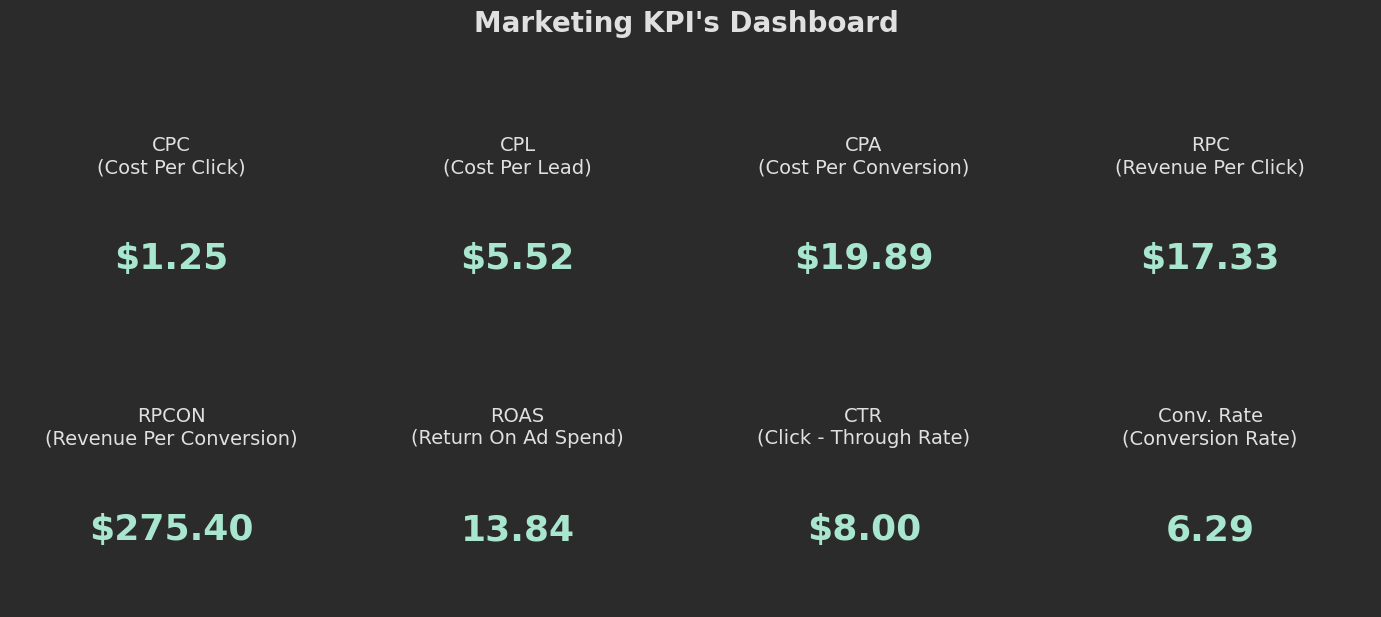

In [42]:
fig, axes = plt.subplots(2, 4, figsize = (14, 6))
fig.patch.set_facecolor('#2b2b2b')

axes = axes.flatten()
light_green = '#a8e6cf'
text_color = '#e0e0e0'

for ax, (title, value) in zip(axes, kpis.items()):
  ax.set_facecolor('#2b2b2b')
  ax.axis('off')

  ax.text(0.5, 0.7, title, ha = 'center', va = 'center', fontsize = 14, color = text_color, fontweight = 'medium')
  ax.text(0.5, 0.3, value, ha = 'center', va = 'center', fontsize = 26, color = light_green, fontweight = 'bold')


plt.suptitle("Marketing KPI's Dashboard", color = text_color, fontsize = 20, fontweight = 'bold', y = 1.02)
plt.tight_layout()
plt.show()

## **Graphical Representation**

Required Libraries

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Loading Dataset

In [44]:
df = pd.read_excel('/content/sample_data/Marketing_Analytics.xlsx')
df.head(5)

,Campaign_ID,Campaign_Type,Region,Age_Group,Gender,Channel,Impressions,Month,Customer_Satisfaction,Bounce_Rate,Session_Duration,Device,Clicks,CTR,Leads,Conversions,Conversion_Rate,Ad_Spend,Revenue,ROI
0,CMP00001,PPC,South,18-25,Male,Google Ads,13434,Jul,1.7,68.29,2.17,Desktop,1148,8.55,61,14,22.95,3079.54,1348.15,-56.22
1,CMP00002,Influencer,South,36-45,Female,Facebook,63185,May,2.3,67.20,1.94,Tablet,7151,11.32,2196,321,14.62,2592.70,96647.90,3627.69
2,CMP00003,SEO,East,46-60,Male,Email,47096,Dec,2.5,31.97,10.78,Tablet,6269,13.31,991,326,32.90,4641.84,92599.81,1894.89
3,CMP00004,Influencer,West,18-25,Male,Google Ads,48471,Oct,3.0,47.23,5.05,Desktop,2000,4.13,402,141,35.07,5572.66,63656.12,1042.29
4,CMP00005,Influencer,North,46-60,Male,Instagram,57004,Mar,1.1,70.10,13.16,Mobile,2696,4.73,661,194,29.35,378.58,58755.38,15419.94


In [45]:
bg_color = '#2b2b2b'
text_color = '#e0e0e0'
accent_1 = '#a8e6cf'
accent_2 = '#dcedc1'
accent_3 = '#ffd3b6'
accent_4 = '#ffaaa5'

plt.rcParams.update({
    'axes.facecolor': bg_color, 'figure.facecolor': bg_color,
    'text.color': text_color, 'axes.labelcolor': text_color,
    'xtick.color': text_color, 'ytick.color': text_color,
    'axes.edgecolor': '#404040', 'grid.color': bg_color,
    'axes.grid': True, 'grid.alpha': 0.3

})

1. Highest Revenue Campaign Type

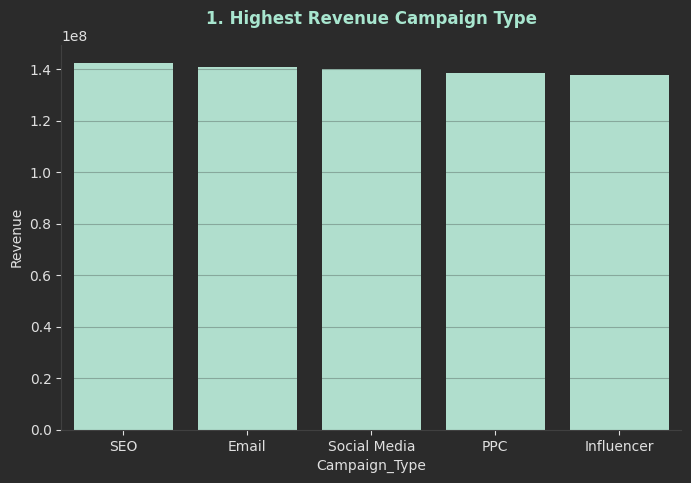

In [46]:
plt.figure(figsize = (8, 5))
campaign_rev = df.groupby('Campaign_Type')['Revenue'].sum().reset_index().sort_values(by = 'Revenue', ascending = False)
sns.barplot(data = campaign_rev, x = 'Campaign_Type', y = 'Revenue', color = accent_1)
plt.title('1. Highest Revenue Campaign Type', pad = 15, color = accent_1, fontweight = 'bold',)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

2. Best Performing Marketing Channel

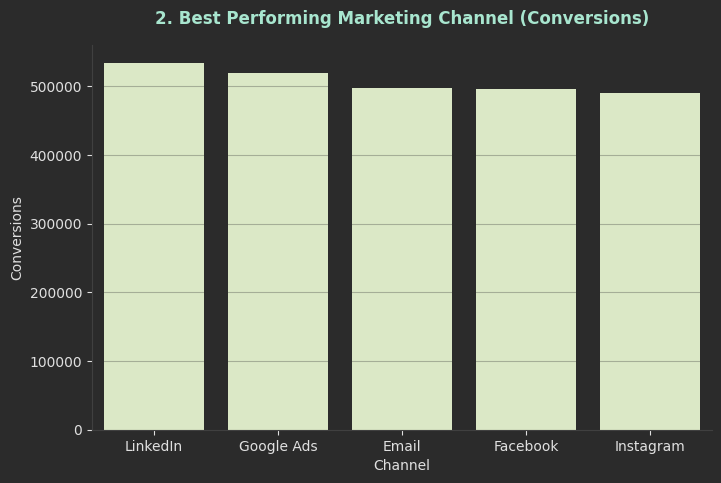

In [47]:
plt.figure(figsize = (8, 5))
channel_conv = df.groupby('Channel')['Conversions'].sum().reset_index().sort_values(by = 'Conversions', ascending = False)
sns.barplot(data = channel_conv, x = 'Channel', y = 'Conversions', color = accent_2)
plt.title('2. Best Performing Marketing Channel (Conversions)', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

3. Peak Revenue Month

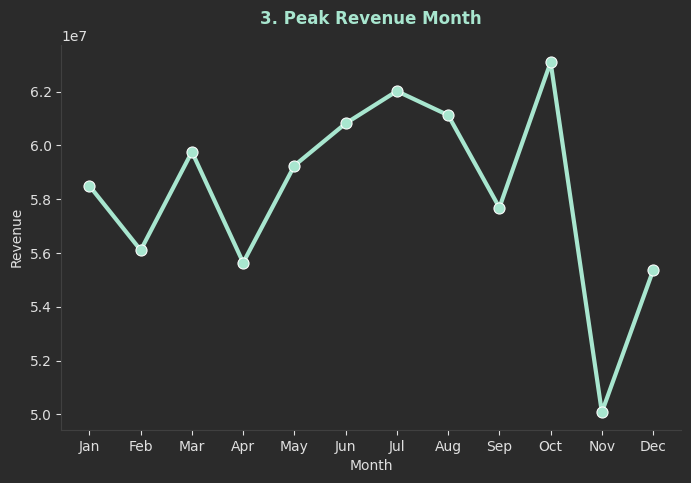

In [48]:
plt.figure(figsize = (8, 5))
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_rev = df.groupby('Month')['Revenue'].sum().reindex(months).reset_index()
sns.lineplot(data = month_rev, x = 'Month', y = 'Revenue', color = accent_1, marker = 'o', linewidth = 3, markersize = 8)
plt.title('3. Peak Revenue Month', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

4. Device with Maximum Conversions

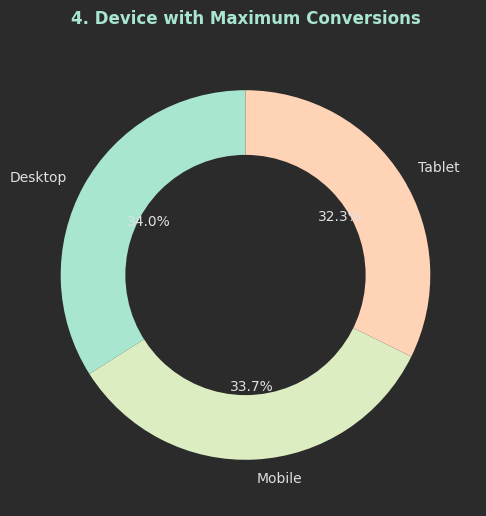

In [49]:
plt.figure(figsize = (6, 6))
device_conv = df.groupby('Device')['Conversions'].sum().reset_index()
plt.pie(device_conv['Conversions'], labels = device_conv['Device'], colors = [accent_1, accent_2, accent_3], autopct = '%1.1f%%', textprops = {'color': text_color}, startangle = 90)
centre_circle = plt.Circle((0,0), 0.65, fc = bg_color)
plt.gca().add_artist(centre_circle)
plt.title('4. Device with Maximum Conversions', pad = 15, color = accent_1, fontweight = 'bold')
plt.show()

5. Region Contributing Highest Revenue

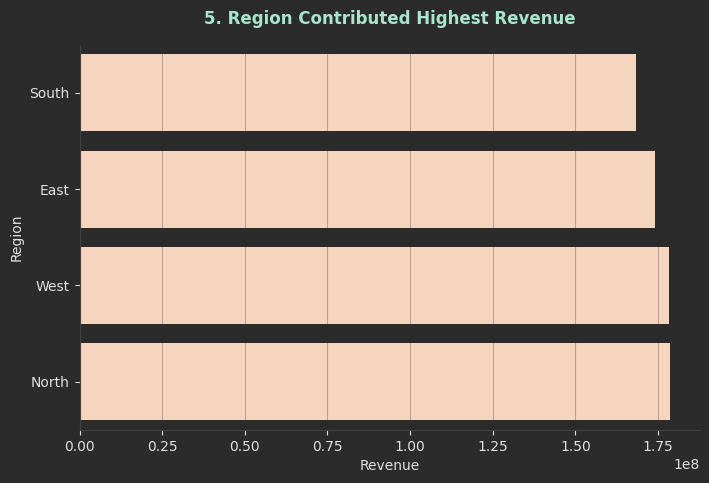

In [50]:
plt.figure(figsize = (8 , 5))
region_rev = df.groupby('Region')['Revenue'].sum().reset_index().sort_values(by = 'Revenue', ascending = True)
sns.barplot(data = region_rev, y = 'Region', x = 'Revenue', color = accent_3)
plt.title('5. Region Contributed Highest Revenue', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

6. CTR vs Conversion Rate

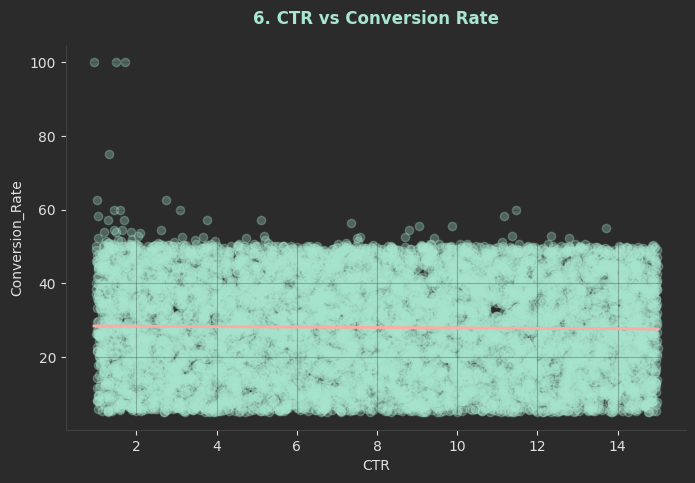

In [51]:
plt.figure(figsize = (8 , 5))
sns.regplot(data = df, x = 'CTR', y = 'Conversion_Rate', scatter_kws = {'color' : accent_1, 'alpha': 0.3}, line_kws = {'color' : accent_4, 'linewidth': 2})
plt.title('6. CTR vs Conversion Rate', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

7. Overall ROI Distribution

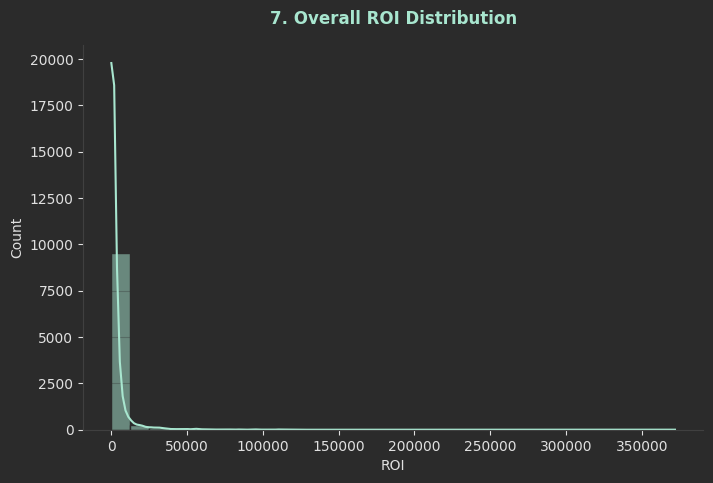

In [52]:
plt.figure(figsize = (8, 5))
sns.histplot(df['ROI'], bins = 30, color = accent_1, kde = True, edgecolor = bg_color)
plt.title('7. Overall ROI Distribution', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

8. Spend Efficiency (Ad Spend vs Revenue)

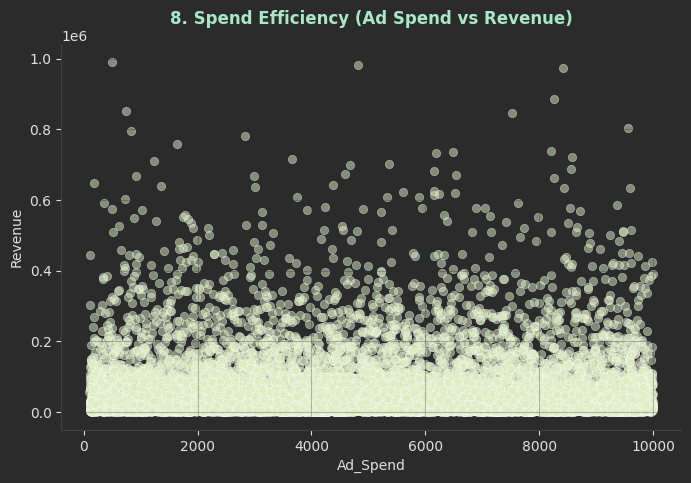

In [53]:
plt.figure(figsize = (8 ,5))
sns.scatterplot(data = df, x = 'Ad_Spend', y = 'Revenue', color = accent_2, alpha = 0.5)
plt.title('8. Spend Efficiency (Ad Spend vs Revenue)', pad = 15, color = accent_1, fontweight = 'bold')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()